# Python Pandas Demo - Data Analytics Workshop

This notebook demonstrates comprehensive data analysis using Python Pandas. We'll cover data types, DataFrame operations, data processing, visualization, and more.

## Learning Objectives
- Review Python data types and their usage in pandas
- Learn DataFrame creation and basic operations
- Practice data cleaning and preprocessing
- Explore grouping, aggregation, and filtering
- Implement advanced data manipulation techniques
- Create data visualizations
- Generate summary statistics and reports

In [1]:
# Cell 1: Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")

Libraries imported successfully!
Pandas version: 1.5.3
NumPy version: 1.24.4


## Python Data Types Review

Before diving into pandas, let's review the fundamental Python data types that we'll be working with.

In [2]:
# Cell 2: Python Data Types Review
print("=== PYTHON DATA TYPES RECAP ===")

# Basic data types
integer_val = 42
float_val = 3.14
string_val = "Hello Pandas"
boolean_val = True
list_val = [1, 2, 3, 4, 5]
dict_val = {"name": "John", "age": 30, "city": "New York"}

print(f"Integer: {integer_val} (type: {type(integer_val)})")
print(f"Float: {float_val} (type: {type(float_val)})")
print(f"String: {string_val} (type: {type(string_val)})")
print(f"Boolean: {boolean_val} (type: {type(boolean_val)})")
print(f"List: {list_val} (type: {type(list_val)})")
print(f"Dictionary: {dict_val} (type: {type(dict_val)})")

=== PYTHON DATA TYPES RECAP ===
Integer: 42 (type: <class 'int'>)
Float: 3.14 (type: <class 'float'>)
String: Hello Pandas (type: <class 'str'>)
Boolean: True (type: <class 'bool'>)
List: [1, 2, 3, 4, 5] (type: <class 'list'>)
Dictionary: {'name': 'John', 'age': 30, 'city': 'New York'} (type: <class 'dict'>)


## Creating a Simulated Dataset

We'll create a realistic customer dataset to demonstrate pandas capabilities. This dataset will include various data types and some missing values to make it more realistic.

In [ ]:
# Cell 3: Create Simulated Dataset
print("\n=== CREATING SIMULATED DATASET ===")

# Set random seed for reproducibility
np.random.seed(42)

# Generate sample data
n_customers = 1000

# Customer data
customer_data = {
    "customer_id": range(1, n_customers + 1),
    "name": [f"Customer_{i}" for i in range(1, n_customers + 1)],
    "age": np.random.randint(18, 80, n_customers),
    "gender": np.random.choice(
        ["Male", "Female", "Other"], n_customers, p=[0.45, 0.45, 0.1]
    ),
    "city": np.random.choice(
        ["New York", "Los Angeles", "Chicago", "Houston", "Phoenix"], n_customers
    ),
    "registration_date": pd.date_range(
        start="2020-01-01", end="2024-01-01", periods=n_customers
    ),
    "total_purchases": np.random.randint(1, 50, n_customers),
    "total_spent": np.round(np.random.normal(500, 200, n_customers), 2),
    "is_premium": np.random.choice([True, False], n_customers, p=[0.3, 0.7]),
}

# Create DataFrame
df = pd.DataFrame(customer_data)

# Add some missing values to make it realistic
missing_indices = np.random.choice(df.index, size=50, replace=False)
df.loc[missing_indices, "total_spent"] = np.nan

print(f"Dataset created with {df.shape[0]} rows and {df.shape[1]} columns")
print("\nFirst 5 rows:")
print(df.head())


=== CREATING SIMULATED DATASET ===
Dataset created with 1000 rows and 9 columns

First 5 rows:
   customer_id        name  age  gender     city  \
0            1  Customer_1   56    Male  Chicago   
1            2  Customer_2   69  Female  Houston   
2            3  Customer_3   46    Male  Phoenix   
3            4  Customer_4   32  Female  Phoenix   
4            5  Customer_5   60  Female  Chicago   

              registration_date  total_purchases  total_spent  is_premium  
0 2020-01-01 00:00:00.000000000                1       358.12       False  
1 2020-01-02 11:05:56.756756756               40       875.23       False  
2 2020-01-03 22:11:53.513513513               44       123.91       False  
3 2020-01-05 09:17:50.270270270               19       598.63        True  
4 2020-01-06 20:23:47.027027027               12       758.28       False  


## Basic DataFrame Exploration

Let's explore our dataset to understand its structure, data types, and basic statistics.

In [4]:
# Cell 4: Basic DataFrame Information
print("\n=== BASIC DATAFRAME EXPLORATION ===")

print("DataFrame Info:")
print(df.info())

print("\nDataFrame Shape:", df.shape)
print("Column Names:", list(df.columns))
print("Data Types:")
print(df.dtypes)

print("\nBasic Statistics:")
print(df.describe())


=== BASIC DATAFRAME EXPLORATION ===
DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   customer_id        1000 non-null   int64         
 1   name               1000 non-null   object        
 2   age                1000 non-null   int64         
 3   gender             1000 non-null   object        
 4   city               1000 non-null   object        
 5   registration_date  1000 non-null   datetime64[ns]
 6   total_purchases    1000 non-null   int64         
 7   total_spent        950 non-null    float64       
 8   is_premium         1000 non-null   bool          
dtypes: bool(1), datetime64[ns](1), float64(1), int64(3), object(3)
memory usage: 63.6+ KB
None

DataFrame Shape: (1000, 9)
Column Names: ['customer_id', 'name', 'age', 'gender', 'city', 'registration_date', 'total_purchases', 'total_spe

## Data Processing with Pandas

Now we'll demonstrate essential data processing techniques including handling missing values, filtering data, and performing grouping operations.

In [5]:
# Cell 5: Data Processing Demonstration
print("\n=== DATA PROCESSING DEMONSTRATION ===")

# 1. Handling Missing Values
print(f"Missing values per column:")
print(df.isnull().sum())

# Fill missing values with median
df['total_spent'].fillna(df['total_spent'].median(), inplace=True)
print(f"\nMissing values after filling: {df.isnull().sum().sum()}")


=== DATA PROCESSING DEMONSTRATION ===
Missing values per column:
customer_id           0
name                  0
age                   0
gender                0
city                  0
registration_date     0
total_purchases       0
total_spent          50
is_premium            0
dtype: int64

Missing values after filling: 0


In [6]:
# 2. Data Filtering
print("\n--- Data Filtering ---")
premium_customers = df[df['is_premium'] == True]
print(f"Premium customers: {len(premium_customers)}")

high_spenders = df[df['total_spent'] > 700]
print(f"High spenders (>$700): {len(high_spenders)}")

young_premium = df[(df['age'] < 30) & (df['is_premium'] == True)]
print(f"Young premium customers: {len(young_premium)}")


--- Data Filtering ---
Premium customers: 305
High spenders (>$700): 166
Young premium customers: 57


In [7]:
# 3. Grouping and Aggregation
print("\n--- Grouping and Aggregation ---")

# Group by city
city_stats = df.groupby('city').agg({
    'total_spent': ['mean', 'sum', 'count'],
    'age': 'mean',
    'total_purchases': 'sum'
}).round(2)

print("Statistics by City:")
print(city_stats)

# Group by gender and premium status
gender_premium_stats = df.groupby(['gender', 'is_premium'])['total_spent'].agg(['mean', 'count']).round(2)
print("\nSpending by Gender and Premium Status:")
print(gender_premium_stats)


--- Grouping and Aggregation ---
Statistics by City:
            total_spent                     age total_purchases
                   mean        sum count   mean             sum
city                                                           
Chicago          495.50   91172.44   184  50.22            4623
Houston          499.82  112960.22   226  49.98            5718
Los Angeles      513.86   96091.14   187  49.30            5083
New York         511.12  101712.54   199  48.23            5079
Phoenix          504.61  102940.00   204  51.49            5089

Spending by Gender and Premium Status:
                     mean  count
gender is_premium               
Female False       515.40    337
       True        510.98    158
Male   False       487.80    292
       True        497.25    118
Other  False       522.69     66
       True        511.71     29


## Advanced Data Manipulation

Let's explore more advanced pandas features including creating new columns, date operations, and data ranking.

In [8]:
# Cell 6: Advanced Data Manipulation
print("\n=== ADVANCED DATA MANIPULATION ===")

# 1. Create new columns
df['avg_purchase_value'] = df['total_spent'] / df['total_purchases']
df['customer_segment'] = pd.cut(df['total_spent'], 
                               bins=[0, 300, 600, 1000, float('inf')], 
                               labels=['Low', 'Medium', 'High', 'VIP'])

# 2. Date operations
df['days_since_registration'] = (pd.Timestamp.now() - df['registration_date']).dt.days
df['registration_year'] = df['registration_date'].dt.year

print("New columns created:")
print(f"- avg_purchase_value: {df['avg_purchase_value'].describe().round(2)}")
print(f"- customer_segment distribution:")
print(df['customer_segment'].value_counts())

# 3. Sorting and ranking
top_spenders = df.nlargest(10, 'total_spent')[['name', 'total_spent', 'customer_segment']]
print(f"\nTop 10 Spenders:")
print(top_spenders)


=== ADVANCED DATA MANIPULATION ===
New columns created:
- avg_purchase_value: count    1000.00
mean       44.54
std        82.01
min       -22.17
25%        12.64
50%        19.38
75%        39.22
max       853.14
Name: avg_purchase_value, dtype: float64
- customer_segment distribution:
Medium    557
High      297
Low       135
VIP         2
Name: customer_segment, dtype: int64

Top 10 Spenders:
             name  total_spent customer_segment
987  Customer_988      1036.87              VIP
441  Customer_442      1012.51              VIP
528  Customer_529       995.88             High
810  Customer_811       985.83             High
728  Customer_729       966.66             High
16    Customer_17       957.96             High
529  Customer_530       953.44             High
421  Customer_422       947.26             High
334  Customer_335       937.61             High
777  Customer_778       936.47             High


## Data Visualization

Visualizations help us understand patterns and insights in our data. We'll create several different types of plots to explore our customer dataset.


=== DATA VISUALIZATION ===


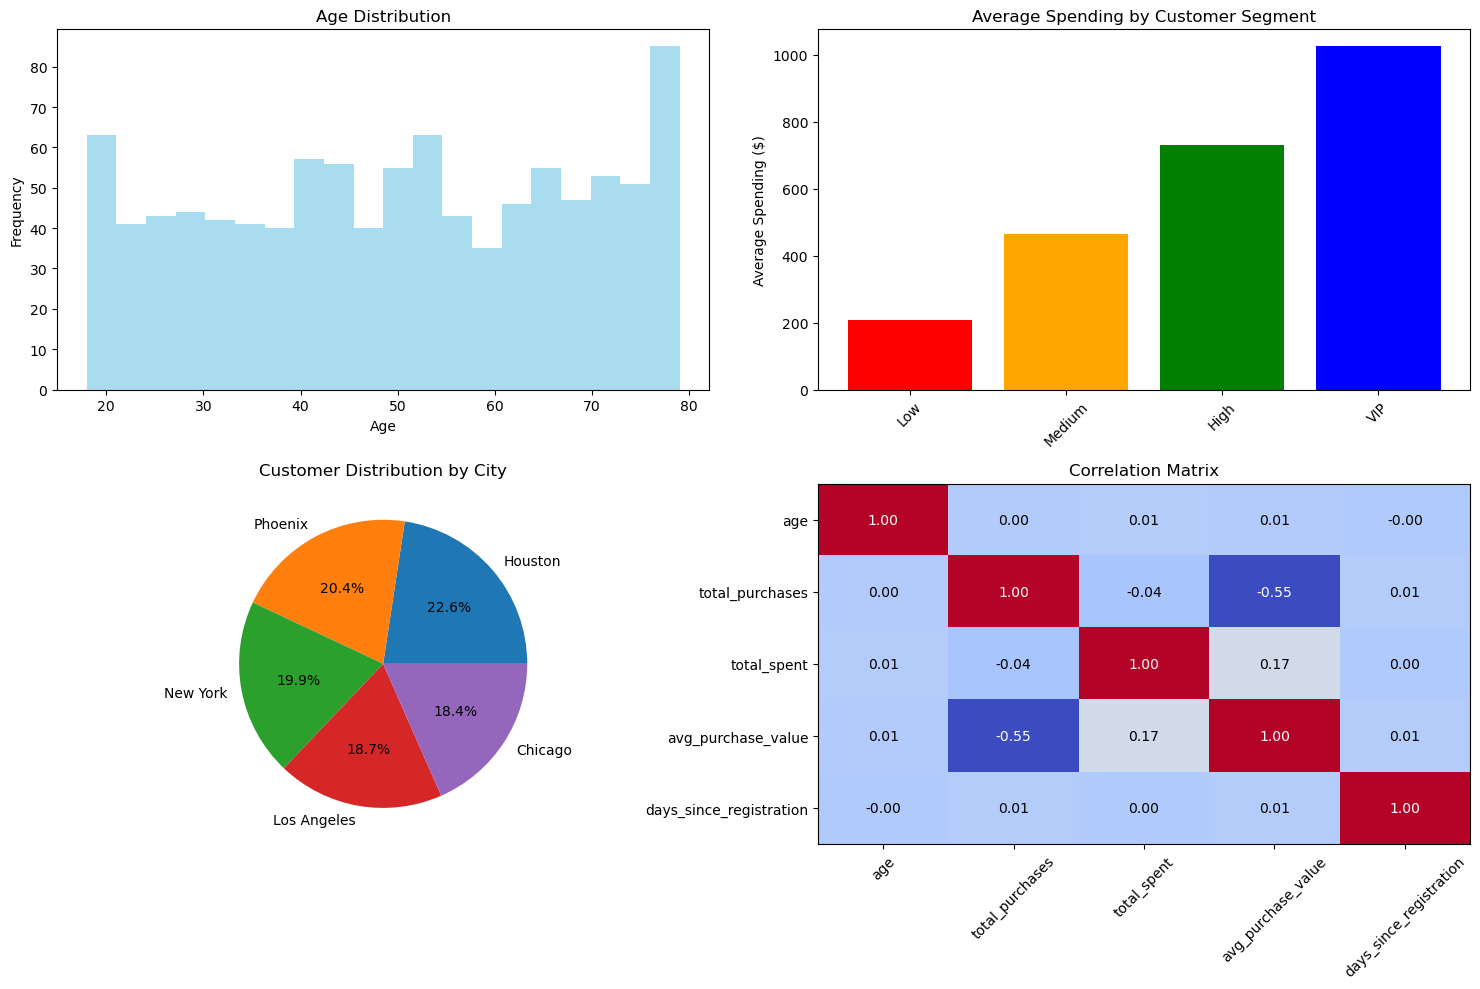

In [9]:
# Cell 7: Data Visualization
print("\n=== DATA VISUALIZATION ===")

# Set up the plotting style
plt.style.use('default')
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Age distribution
axes[0, 0].hist(df['age'], bins=20, alpha=0.7, color='skyblue')
axes[0, 0].set_title('Age Distribution')
axes[0, 0].set_xlabel('Age')
axes[0, 0].set_ylabel('Frequency')

# 2. Spending by customer segment
segment_spending = df.groupby('customer_segment')['total_spent'].mean()
axes[0, 1].bar(segment_spending.index, segment_spending.values, color=['red', 'orange', 'green', 'blue'])
axes[0, 1].set_title('Average Spending by Customer Segment')
axes[0, 1].set_ylabel('Average Spending ($)')
axes[0, 1].tick_params(axis='x', rotation=45)

# 3. City-wise customer count
city_counts = df['city'].value_counts()
axes[1, 0].pie(city_counts.values, labels=city_counts.index, autopct='%1.1f%%')
axes[1, 0].set_title('Customer Distribution by City')

# 4. Correlation heatmap
numeric_cols = ['age', 'total_purchases', 'total_spent', 'avg_purchase_value', 'days_since_registration']
correlation_matrix = df[numeric_cols].corr()
im = axes[1, 1].imshow(correlation_matrix, cmap='coolwarm', aspect='auto')
axes[1, 1].set_xticks(range(len(numeric_cols)))
axes[1, 1].set_yticks(range(len(numeric_cols)))
axes[1, 1].set_xticklabels(numeric_cols, rotation=45)
axes[1, 1].set_yticklabels(numeric_cols)
axes[1, 1].set_title('Correlation Matrix')

# Add correlation values
for i in range(len(numeric_cols)):
    for j in range(len(numeric_cols)):
        axes[1, 1].text(j, i, f'{correlation_matrix.iloc[i, j]:.2f}', 
                       ha='center', va='center', color='white' if abs(correlation_matrix.iloc[i, j]) > 0.5 else 'black')

plt.tight_layout()
plt.show()

## Data Export and Summary

Finally, let's create a summary report and export our processed data for future use.

In [10]:
# Cell 8: Data Export and Summary
print("\n=== DATA EXPORT AND SUMMARY ===")

# Create summary report
summary_report = {
    'Total Customers': len(df),
    'Average Age': df['age'].mean().round(1),
    'Average Spending': df['total_spent'].mean().round(2),
    'Premium Customers': len(df[df['is_premium'] == True]),
    'Top City': df['city'].mode()[0],
    'Most Common Segment': df['customer_segment'].mode()[0]
}

print("Summary Report:")
for key, value in summary_report.items():
    print(f"- {key}: {value}")

# Save processed data
df.to_csv('processed_customer_data.csv', index=False)
print(f"\nProcessed data saved to 'processed_customer_data.csv'")


=== DATA EXPORT AND SUMMARY ===
Summary Report:
- Total Customers: 1000
- Average Age: 49.9
- Average Spending: 504.88
- Premium Customers: 305
- Top City: Houston
- Most Common Segment: Medium

Processed data saved to 'processed_customer_data.csv'


## Summary

### Demo Completed! 🎉

This demonstration covered:

1. **Python data types** and their usage in pandas
2. **DataFrame creation** and basic operations
3. **Data cleaning** and preprocessing
4. **Grouping, aggregation, and filtering**
5. **Advanced data manipulation**
6. **Data visualization**
7. **Summary statistics** and reporting

### Key Takeaways:
- Pandas is powerful for data manipulation and analysis
- DataFrames provide a flexible structure for structured data
- Combining filtering, grouping, and visualization reveals data insights
- Proper data preprocessing is essential for meaningful analysis

### Next Steps:
- Experiment with your own datasets
- Explore more advanced pandas features
- Try different visualization libraries like Plotly or Bokeh
- Learn about data modeling and machine learning with scikit-learn